# Brain Tumor MRI Classification — MobileNetV2 (20 Epochs)


Found 2144 images belonging to 3 classes.
Found 458 images belonging to 3 classes.
Found 462 images belonging to 3 classes.
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


67/67 - 71s - 1s/step - accuracy: 0.6931 - loss: 0.6697 - val_accuracy: 0.8493 - val_loss: 0.3995
Epoch 2/20
67/67 - 60s - 900ms/step - accuracy: 0.8456 - loss: 0.4057 - val_accuracy: 0.8493 - val_loss: 0.3543
Epoch 3/20
67/67 - 60s - 901ms/step - accuracy: 0.8689 - loss: 0.3120 - val_accuracy: 0.8799 - val_loss: 0.3194
Epoch 4/20
67/67 - 61s - 905ms/step - accuracy: 0.8909 - loss: 0.2881 - val_accuracy: 0.8908 - val_loss: 0.3110
Epoch 5/20
67/67 - 73s - 1s/step - accuracy: 0.9053 - loss: 0.2461 - val_accuracy: 0.8799 - val_loss: 0.3031
Epoch 6/20
67/67 - 70s - 1s/step - accuracy: 0.9076 - loss: 0.2348 - val_accuracy: 0.8734 - val_loss: 0.3138
Epoch 7/20
67/67 - 73s - 1s/step - accuracy: 0.9123 - loss: 0.2210 - val_accuracy: 0.8646 - val_loss: 0.3255
Epoch 8/20
67/67 - 68s - 1s/step - accuracy: 0.9254 - loss: 0.2005 - val_accuracy: 0.8777 - val_loss: 0.2912
Epoch 9/20
67/67 - 68s - 1s/step - accuracy: 0.9375 - loss: 0.1797 - val_accuracy: 0.8799 - val_loss: 0.2870
Epoch 10/20
67/67 - 6

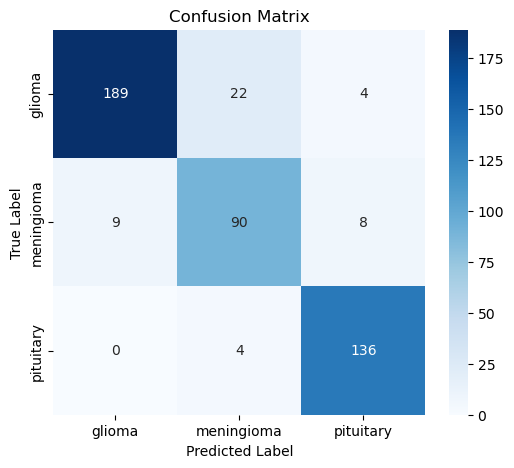

🔢 Precision-Recall AUC for class 2: 0.95


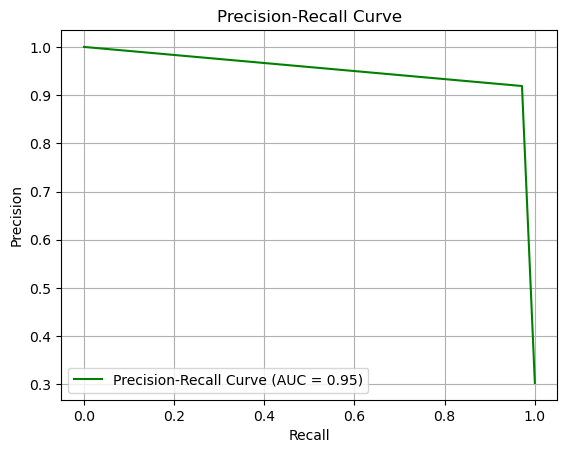

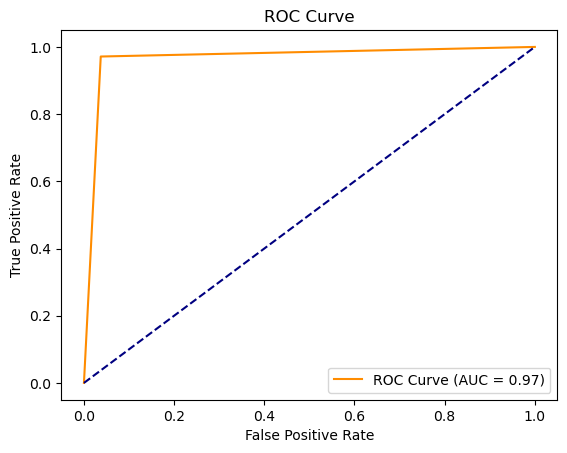

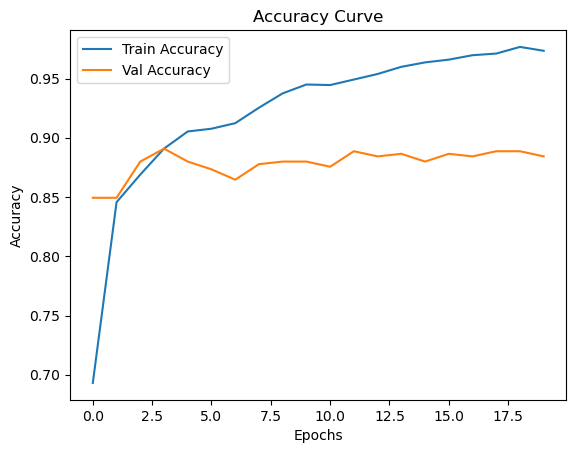

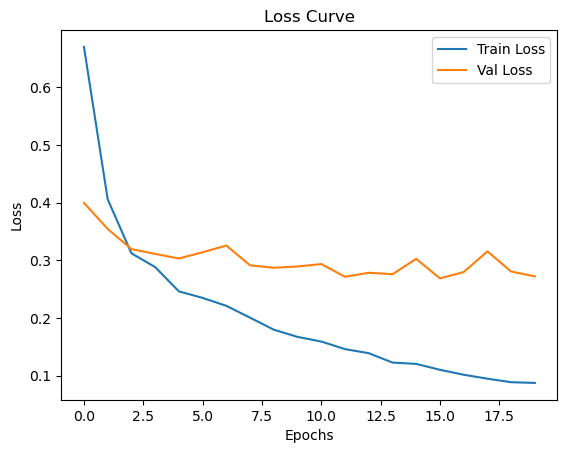

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, roc_curve, auc, confusion_matrix, classification_report
import seaborn as sns
import os

# Base data directory
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'

# Paths
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Image parameters
img_height, img_width = 224, 224
batch_size = 32

# ImageDataGenerator (rescale only)
datagen = ImageDataGenerator(rescale=1./255)

# Load data
train_data = datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

val_data = datagen.flow_from_directory(
    val_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

test_data = datagen.flow_from_directory(
    test_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# Model setup
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=x)

model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train for 10 epochs only (no further training will occur after this)
history = model.fit(
    train_data,
    epochs=20,
    validation_data=val_data,
    callbacks=[early_stopping],
    verbose=2
)


# Evaluation on test set
test_loss, test_acc = model.evaluate(test_data)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Predictions
test_labels = test_data.classes
test_preds = model.predict(test_data)
test_preds = np.argmax(test_preds, axis=1)

# Confusion Matrix and Report
conf_matrix = confusion_matrix(test_labels, test_preds)
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=test_data.class_indices.keys()))

# Confusion Matrix Plot
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.class_indices.keys(),
            yticklabels=test_data.class_indices.keys())
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Precision-Recall Curve (for class index 2)
precision, recall, _ = precision_recall_curve(test_labels == 2, test_preds == 2)
pr_auc = auc(recall, precision)
print(f"🔢 Precision-Recall AUC for class 2: {pr_auc:.2f}")

plt.figure()
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {pr_auc:.2f})', color='green')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(test_labels == 2, test_preds == 2)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Plot Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [4]:
model.save('Mobilenetv2 model_20 epochs.h5')  # Save the model
print("Model saved successfully!")


Model saved successfully!


In [1]:
import time
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# === PATHS ===
model_path = r"C:\Users\usER\Downloads\Mobilenetv2 model_20 epochs.h5"
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\test\glioma\3061.jpg"

# === Load Model ===
model = load_model(model_path)
print("✅ Model loaded successfully.")

# === Load and Preprocess Image ===
img = load_img(image_path, target_size=(224, 224))  # adjust to your model input
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)  # shape: (1, 224, 224, 3)

# === Measure Inference Time ===
start = time.time()
_ = model.predict(img_array)
end = time.time()

inference_time_ms = (end - start) * 1000
print(f"🕒 Inference Time: {inference_time_ms:.2f} ms")

# === Measure Model Size ===
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"💾 Model Size: {model_size_mb:.2f} MB")


✅ Model loaded successfully.
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
🕒 Inference Time: 1577.46 ms
💾 Model Size: 14.14 MB


Found 462 images belonging to 3 classes.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.88      0.92       215
  meningioma       0.78      0.84      0.81       107
   pituitary       0.92      0.97      0.94       140

    accuracy                           0.90       462
   macro avg       0.88      0.90      0.89       462
weighted avg       0.90      0.90      0.90       462



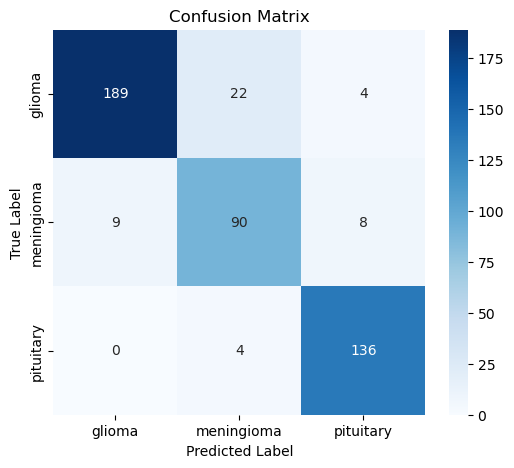

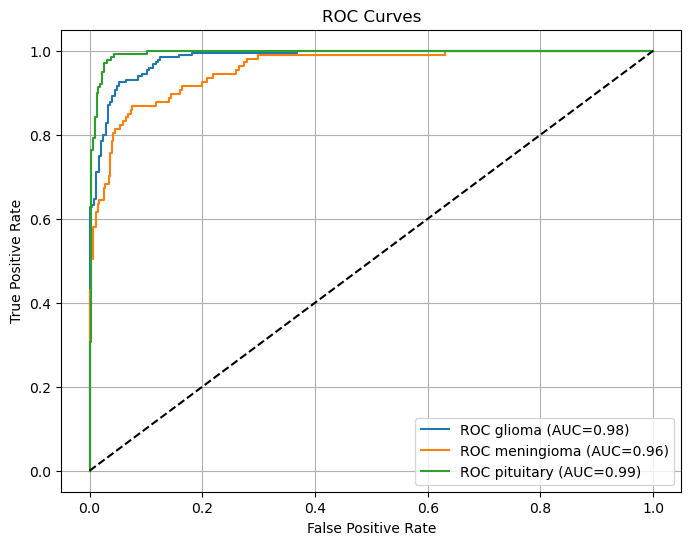

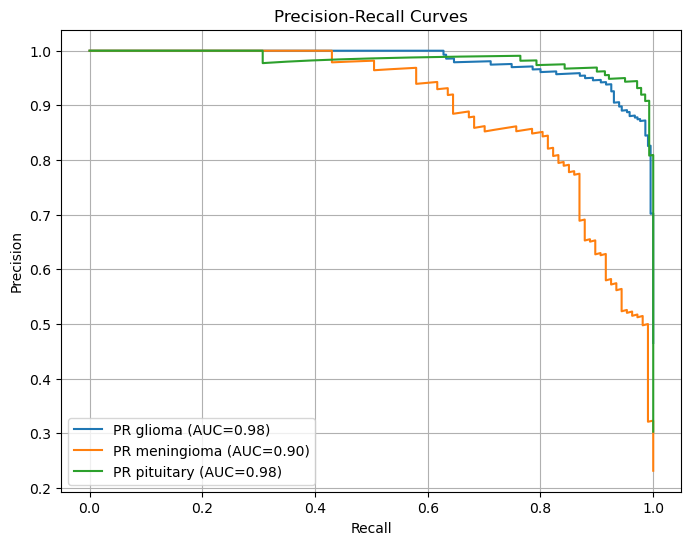

In [5]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load model
model = load_model('Mobilenetv2 model_20 epochs.h5')

# Data setup
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
test_dir = os.path.join(base_dir, 'test')
img_height, img_width = 224, 224
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

test_labels = test_data.classes
class_names = list(test_data.class_indices.keys())
n_classes = len(class_names)

# Predictions
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix & report (optional)
from sklearn.metrics import confusion_matrix, classification_report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=class_names))

# Plot Confusion Matrix (optional)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Binarize labels for multi-class metrics
y_true_bin = label_binarize(test_labels, classes=range(n_classes))

# ROC Curve and AUC per class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], test_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC {class_names[i]} (AUC={roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve and AUC per class
precision = dict()
recall = dict()
pr_auc = dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], test_preds[:, i])
    pr_auc[i] = auc(recall[i], precision[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label=f'PR {class_names[i]} (AUC={pr_auc[i]:.2f})')
plt.title('Precision-Recall Curves')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()
